In [ ]:
# import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import string
import re
import joblib
import json
from collections import Counter
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import pickle

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import plot_model
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Embedding, Dense, Flatten, Conv1D, MaxPooling1D, SimpleRNN, GRU, LSTM, LSTM, Input, Embedding, TimeDistributed, Flatten, Dropout,Bidirectional
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau


In [ ]:
import nltk
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving polo.json to polo.json


In [ ]:
with open('polo.json') as file:
  data = json.load(file)

In [ ]:
# convert to dataframes

def frame_data(feat_1,feat_2,is_pattern):
  is_pattern = is_pattern
  df = pd.DataFrame(columns=[feat_1,feat_2])
  for intent in data['intents']:
    if is_pattern:
      for pattern in intent['patterns']:
        w = pattern
        df_to_append = pd.Series([w,intent['tag']], index = df.columns)
        df = df.append(df_to_append,ignore_index=True)
    else:
      for response in intent['responses']:
        w = response
        df_to_append = pd.Series([w,intent['tag']], index = df.columns)
        df = df.append(df_to_append,ignore_index=True)
  return df

In [ ]:
df1 = frame_data('questions','labels',True)
df1.head()

,questions,labels
0,What is cryptocurrency?,cryptocurrency
1,Describe cryptocurrency,cryptocurrency
2,What is blockchain?,blockchain
3,How do blockchain works?,blockchain
4,What is bitcoin?,bitcoin


In [ ]:
# no of patterns

(df1.labels.value_counts(sort=False))

cryptocurrency    2
blockchain        2
bitcoin           2
ethereum          2
tether            2
dogecoin          2
ripple            2
shiba             2
binance           2
polo              2
Name: labels, dtype: int64

In [ ]:
df2 = frame_data('response','labels',False)
df2.head()

,response,labels
0,Cryptocurrency is basically a digital form of ...,cryptocurrency
1,Blockchain helps in secure transfer of the own...,blockchain
2,"Bitcoin (BTC) is a cryptocurrency, a virtual c...",bitcoin
3,"Bitcoin (BTC) is a cryptocurrency, a virtual c...",ethereum
4,"Bitcoin (BTC) is a cryptocurrency, a virtual c...",tether


In [ ]:
# preprocessing text

lemmatizer = WordNetLemmatizer()

vocab = Counter()
labels = []
def tokenizer(entry):
    tokens = entry.split()
    re_punc = re.compile('[%s]' % re.escape(string.punctuation))
    tokens = [re_punc.sub('', w) for w in tokens]
    tokens = [word for word in tokens if word.isalpha()]
    tokens = [lemmatizer.lemmatize(w.lower()) for w in tokens]
    tokens = [word.lower() for word in tokens if len(word) > 1]
    return tokens

def remove_stop_words(tokenizer,df,feature):
    doc_without_stopwords = []
    for entry in df[feature]:
        tokens = tokenizer(entry)
        joblib.dump(tokens,'tokens.pkl')
        doc_without_stopwords.append(' '.join(tokens))
    df[feature] = doc_without_stopwords
    return

In [ ]:
def create_vocab(tokenizer,df,feature):
    for entry in df[feature]:
        tokens = tokenizer(entry)
        vocab.update(tokens)
    joblib.dump(vocab,'vocab.pkl')
    return

In [ ]:
create_vocab(tokenizer,df1,'questions')

In [ ]:
vocab

Counter({'what': 10,
         'is': 10,
         'cryptocurrency': 2,
         'describe': 9,
         'blockchain': 2,
         'how': 1,
         'do': 1,
         'work': 1,
         'bitcoin': 2,
         'ethereum': 2,
         'tether': 2,
         'dogecoin': 2,
         'ripple': 2,
         'shiba': 2,
         'binance': 2,
         'polo': 2})

In [ ]:
vocab_size = len(vocab)
vocab_size

16

In [ ]:
df1.groupby(by='labels',as_index=False).first()['questions']

0           What is binance?
1           What is bitcoin?
2        What is blockchain?
3    What is cryptocurrency?
4          What is dogecoin?
5          What is ethereum?
6              What is polo?
7            What is ripple?
8             What is shiba?
9            What is tether?
Name: questions, dtype: object

In [ ]:
# test_list contains the first element of questions

test_list = list(df1.groupby(by='labels',as_index=False).first()['questions'])
test_list

['What is binance?',
 'What is bitcoin?',
 'What is blockchain?',
 'What is cryptocurrency?',
 'What is dogecoin?',
 'What is ethereum?',
 'What is polo?',
 'What is ripple?',
 'What is shiba?',
 'What is tether?']

In [ ]:
# indices of the testing dataset

test_index = []
for i,_ in enumerate(test_list):
    idx = df1[df1.questions == test_list[i]].index[0]
    test_index.append(idx)
test_index

[16, 4, 2, 0, 10, 6, 18, 12, 14, 8]

In [ ]:
# train indices are the all indices minus the testing indices

train_index = [i for i in df1.index if i not in test_index]
train_index

[1, 3, 5, 7, 9, 11, 13, 15, 17, 19]

In [ ]:
def convert_seq(df,feature):
#     text = ' '.join(list(vocab.keys()))
    t = Tokenizer()
    entries = [entry for entry in df[feature]]
    print(entries)
    print('----')
    t.fit_on_texts(entries)
    joblib.dump(t,'tokenizer_t.pkl')   # why a pkl file
    vocab_size = len(t.word_index) +1 # +1 for oov
    print(t.word_index)
    entries = [entry for entry in df[feature]]
    max_length = max([len(s.split()) for s in entries])
    print('----')
    print("max length of string is : ",max_length)
    print('----')
    encoded = t.texts_to_sequences(entries)
    print(encoded)
    padded = pad_sequences(encoded, maxlen=max_length, padding='post')
    print('----')
    print(padded)
    return padded, vocab_size

In [ ]:
X,vocab_size = convert_seq(df1,'questions')

['What is cryptocurrency?', 'Describe cryptocurrency', 'What is blockchain?', 'How do blockchain works?', 'What is bitcoin?', 'Describe bitcoin', 'What is ethereum?', 'Describe ethereum', 'What is tether?', 'Describe tether', 'What is dogecoin?', 'Describe dogecoin', 'What is ripple?', 'Describe ripple', 'What is shiba?', 'Describe shiba', 'What is binance?', 'Describe binance', 'What is polo?', 'Describe polo']
----
{'what': 1, 'is': 2, 'describe': 3, 'cryptocurrency': 4, 'blockchain': 5, 'bitcoin': 6, 'ethereum': 7, 'tether': 8, 'dogecoin': 9, 'ripple': 10, 'shiba': 11, 'binance': 12, 'polo': 13, 'how': 14, 'do': 15, 'works': 16}
----
max length of string is :  4
----
[[1, 2, 4], [3, 4], [1, 2, 5], [14, 15, 5, 16], [1, 2, 6], [3, 6], [1, 2, 7], [3, 7], [1, 2, 8], [3, 8], [1, 2, 9], [3, 9], [1, 2, 10], [3, 10], [1, 2, 11], [3, 11], [1, 2, 12], [3, 12], [1, 2, 13], [3, 13]]
----
[[ 1  2  4  0]
 [ 3  4  0  0]
 [ 1  2  5  0]
 [14 15  5 16]
 [ 1  2  6  0]
 [ 3  6  0  0]
 [ 1  2  7  0]
 [ 

In [ ]:
with open('tokenizer_t.pkl', 'rb') as f:
    data = pickle.load(f)

In [ ]:
data.index_word


{1: 'what',
 2: 'is',
 3: 'describe',
 4: 'cryptocurrency',
 5: 'blockchain',
 6: 'bitcoin',
 7: 'ethereum',
 8: 'tether',
 9: 'dogecoin',
 10: 'ripple',
 11: 'shiba',
 12: 'binance',
 13: 'polo',
 14: 'how',
 15: 'do',
 16: 'works'}

In [ ]:
data.word_counts

OrderedDict([('what', 10),
             ('is', 10),
             ('cryptocurrency', 2),
             ('describe', 9),
             ('blockchain', 2),
             ('how', 1),
             ('do', 1),
             ('works', 1),
             ('bitcoin', 2),
             ('ethereum', 2),
             ('tether', 2),
             ('dogecoin', 2),
             ('ripple', 2),
             ('shiba', 2),
             ('binance', 2),
             ('polo', 2)])

In [ ]:
X

array([[ 1,  2,  4,  0],
       [ 3,  4,  0,  0],
       [ 1,  2,  5,  0],
       [14, 15,  5, 16],
       [ 1,  2,  6,  0],
       [ 3,  6,  0,  0],
       [ 1,  2,  7,  0],
       [ 3,  7,  0,  0],
       [ 1,  2,  8,  0],
       [ 3,  8,  0,  0],
       [ 1,  2,  9,  0],
       [ 3,  9,  0,  0],
       [ 1,  2, 10,  0],
       [ 3, 10,  0,  0],
       [ 1,  2, 11,  0],
       [ 3, 11,  0,  0],
       [ 1,  2, 12,  0],
       [ 3, 12,  0,  0],
       [ 1,  2, 13,  0],
       [ 3, 13,  0,  0]], dtype=int32)

In [ ]:
vocab_size

17

In [ ]:
df_encoded = pd.DataFrame(X)

In [ ]:
df_encoded

,0,1,2,3
0,1,2,4,0
1,3,4,0,0
2,1,2,5,0
3,14,15,5,16
4,1,2,6,0
5,3,6,0,0
6,1,2,7,0
7,3,7,0,0
8,1,2,8,0
9,3,8,0,0


In [ ]:
df1.head(10)

,questions,labels
0,What is cryptocurrency?,cryptocurrency
1,Describe cryptocurrency,cryptocurrency
2,What is blockchain?,blockchain
3,How do blockchain works?,blockchain
4,What is bitcoin?,bitcoin
5,Describe bitcoin,bitcoin
6,What is ethereum?,ethereum
7,Describe ethereum,ethereum
8,What is tether?,tether
9,Describe tether,tether


In [ ]:
df_encoded['labels'] = df1.labels
df_encoded.head(10)

,0,1,2,3,labels
0,1,2,4,0,cryptocurrency
1,3,4,0,0,cryptocurrency
2,1,2,5,0,blockchain
3,14,15,5,16,blockchain
4,1,2,6,0,bitcoin
5,3,6,0,0,bitcoin
6,1,2,7,0,ethereum
7,3,7,0,0,ethereum
8,1,2,8,0,tether
9,3,8,0,0,tether


In [ ]:
df_encoded

,0,1,2,3,labels
0,1,2,4,0,cryptocurrency
1,3,4,0,0,cryptocurrency
2,1,2,5,0,blockchain
3,14,15,5,16,blockchain
4,1,2,6,0,bitcoin
5,3,6,0,0,bitcoin
6,1,2,7,0,ethereum
7,3,7,0,0,ethereum
8,1,2,8,0,tether
9,3,8,0,0,tether


In [ ]:
from sklearn.preprocessing import LabelEncoder
lable_enc = LabelEncoder()

# encoding the labels

labl = lable_enc.fit_transform(df_encoded.labels)
labl

array([3, 3, 2, 2, 1, 1, 5, 5, 9, 9, 4, 4, 7, 7, 8, 8, 0, 0, 6, 6])

In [ ]:
len(labl)

20

In [ ]:
mapper = {}
for index,key in enumerate(df_encoded.labels):
    if key not in mapper.keys():
        mapper[key] = labl[index]
mapper

{'cryptocurrency': 3,
 'blockchain': 2,
 'bitcoin': 1,
 'ethereum': 5,
 'tether': 9,
 'dogecoin': 4,
 'ripple': 7,
 'shiba': 8,
 'binance': 0,
 'polo': 6}

In [ ]:
df2.head()

,response,labels
0,Cryptocurrency is basically a digital form of ...,cryptocurrency
1,Blockchain helps in secure transfer of the own...,blockchain
2,"Bitcoin (BTC) is a cryptocurrency, a virtual c...",bitcoin
3,"Bitcoin (BTC) is a cryptocurrency, a virtual c...",ethereum
4,"Bitcoin (BTC) is a cryptocurrency, a virtual c...",tether


In [ ]:
df2


,response,labels
0,Cryptocurrency is basically a digital form of ...,cryptocurrency
1,Blockchain helps in secure transfer of the own...,blockchain
2,"Bitcoin (BTC) is a cryptocurrency, a virtual c...",bitcoin
3,"Bitcoin (BTC) is a cryptocurrency, a virtual c...",ethereum
4,"Bitcoin (BTC) is a cryptocurrency, a virtual c...",tether
5,"Bitcoin (BTC) is a cryptocurrency, a virtual c...",dogecoin
6,"Bitcoin (BTC) is a cryptocurrency, a virtual c...",ripple
7,"Bitcoin (BTC) is a cryptocurrency, a virtual c...",shiba
8,"Bitcoin (BTC) is a cryptocurrency, a virtual c...",binance
9,"Bitcoin (BTC) is a cryptocurrency, a virtual c...",polo


In [ ]:
df2.labels = df2.labels.map(mapper).astype({'labels': 'int32'})
df2.head()

,response,labels
0,Cryptocurrency is basically a digital form of ...,3
1,Blockchain helps in secure transfer of the own...,2
2,"Bitcoin (BTC) is a cryptocurrency, a virtual c...",1
3,"Bitcoin (BTC) is a cryptocurrency, a virtual c...",5
4,"Bitcoin (BTC) is a cryptocurrency, a virtual c...",9


In [ ]:
df2.to_csv('response.csv',index=False)

In [ ]:
df_encoded.head()

,0,1,2,3,labels
0,1,2,4,0,cryptocurrency
1,3,4,0,0,cryptocurrency
2,1,2,5,0,blockchain
3,14,15,5,16,blockchain
4,1,2,6,0,bitcoin


In [ ]:
train_index

[1, 3, 5, 7, 9, 11, 13, 15, 17, 19]

In [ ]:
test_index

[16, 4, 2, 0, 10, 6, 18, 12, 14, 8]

In [ ]:
train = df_encoded.loc[train_index]
test = df_encoded.loc[test_index]

In [ ]:
train

,0,1,2,3,labels
1,3,4,0,0,cryptocurrency
3,14,15,5,16,blockchain
5,3,6,0,0,bitcoin
7,3,7,0,0,ethereum
9,3,8,0,0,tether
11,3,9,0,0,dogecoin
13,3,10,0,0,ripple
15,3,11,0,0,shiba
17,3,12,0,0,binance
19,3,13,0,0,polo


In [ ]:
test.head()

,0,1,2,3,labels
16,1,2,12,0,binance
4,1,2,6,0,bitcoin
2,1,2,5,0,blockchain
0,1,2,4,0,cryptocurrency
10,1,2,9,0,dogecoin


In [ ]:
train.labels.value_counts()

cryptocurrency    1
blockchain        1
bitcoin           1
ethereum          1
tether            1
dogecoin          1
ripple            1
shiba             1
binance           1
polo              1
Name: labels, dtype: int64

In [ ]:
test.labels.value_counts()

binance           1
bitcoin           1
blockchain        1
cryptocurrency    1
dogecoin          1
ethereum          1
polo              1
ripple            1
shiba             1
tether            1
Name: labels, dtype: int64

In [ ]:
train

,0,1,2,3,labels
1,3,4,0,0,cryptocurrency
3,14,15,5,16,blockchain
5,3,6,0,0,bitcoin
7,3,7,0,0,ethereum
9,3,8,0,0,tether
11,3,9,0,0,dogecoin
13,3,10,0,0,ripple
15,3,11,0,0,shiba
17,3,12,0,0,binance
19,3,13,0,0,polo


In [ ]:
X_train = train.drop(columns=['labels'],axis=1)
y_train = train.labels
X_test = test.drop(columns=['labels'],axis=1)
y_test = test.labels

In [ ]:
X_train.head()

,0,1,2,3
1,3,4,0,0
3,14,15,5,16
5,3,6,0,0
7,3,7,0,0
9,3,8,0,0


In [ ]:
y_train =pd.get_dummies(y_train).values
y_test =pd.get_dummies(y_test).values

In [ ]:
X_test

,0,1,2,3
16,1,2,12,0
4,1,2,6,0
2,1,2,5,0
0,1,2,4,0
10,1,2,9,0
6,1,2,7,0
18,1,2,13,0
12,1,2,10,0
14,1,2,11,0
8,1,2,8,0


In [ ]:
X_train

,0,1,2,3
1,3,4,0,0
3,14,15,5,16
5,3,6,0,0
7,3,7,0,0
9,3,8,0,0
11,3,9,0,0
13,3,10,0,0
15,3,11,0,0
17,3,12,0,0
19,3,13,0,0


In [ ]:
y_train

array([[0, 0, 0, 1, 0, 0, 0, 0, 0, 0],
       [0, 0, 1, 0, 0, 0, 0, 0, 0, 0],
       [0, 1, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 1, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 1],
       [0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
       [1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 1, 0, 0, 0]], dtype=uint8)

In [ ]:
y_train[0]

array([0, 0, 0, 1, 0, 0, 0, 0, 0, 0], dtype=uint8)

In [ ]:
y_test

array([[1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 1, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 1, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 1, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 1, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 1]], dtype=uint8)

In [ ]:
y_train[0].shape,y_test[0].shape

((10,), (10,))

In [ ]:
X_train.shape

(10, 4)

In [ ]:

X_test.shape

(10, 4)

In [ ]:
max_length = X_train.shape[1]
output = 16                  # no of classes

In [ ]:
early_stopping = EarlyStopping(monitor='val_loss',patience=10) #patience : number of epochs with no improvement after which training will be stopped

checkpoint = ModelCheckpoint("model-v1.h5",
                             monitor="val_loss",
                             mode="min",
                             save_best_only = True,
                             verbose=1)

reduce_lr = ReduceLROnPlateau(monitor = 'val_loss', factor = 0.2, patience = 3, verbose = 1, min_delta = 0.0001)

callbacks = [early_stopping,checkpoint,reduce_lr]

In [ ]:
def define_model3(vocab_size, max_length):
    model3 = Sequential()
    model3.add(Embedding(vocab_size,300, input_length=4))
    model3.add(LSTM(500))
    model3.add(Dense(10, activation='softmax'))

    model3.compile(loss = 'categorical_crossentropy',optimizer = 'adam',metrics = ['accuracy'])

    # summarize defined model
    model3.summary()
    return model3

In [ ]:
model3 = define_model3(vocab_size, max_length)

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_2 (Embedding)     (None, 4, 300)            5100      
                                                                 
 lstm_2 (LSTM)               (None, 500)               1602000   
                                                                 
 dense_2 (Dense)             (None, 10)                5010      
                                                                 
Total params: 1,612,110
Trainable params: 1,612,110
Non-trainable params: 0
_________________________________________________________________


In [ ]:
history = model3.fit(X_train, y_train, epochs=15, verbose=1,validation_data=(X_test,y_test))

Epoch 1/15
1/1 [==============================] - 3s 3s/step - loss: 2.3026 - accuracy: 0.0000e+00 - val_loss: 2.2894 - val_accuracy: 0.8000
Epoch 2/15
1/1 [==============================] - 0s 79ms/step - loss: 2.2802 - accuracy: 0.8000 - val_loss: 2.2756 - val_accuracy: 0.9000
Epoch 3/15
1/1 [==============================] - 0s 70ms/step - loss: 2.2572 - accuracy: 1.0000 - val_loss: 2.2611 - val_accuracy: 0.9000
Epoch 4/15
1/1 [==============================] - 0s 71ms/step - loss: 2.2324 - accuracy: 1.0000 - val_loss: 2.2456 - val_accuracy: 0.9000
Epoch 5/15
1/1 [==============================] - 0s 83ms/step - loss: 2.2048 - accuracy: 1.0000 - val_loss: 2.2285 - val_accuracy: 0.9000
Epoch 6/15
1/1 [==============================] - 0s 73ms/step - loss: 2.1733 - accuracy: 1.0000 - val_loss: 2.2097 - val_accuracy: 0.9000
Epoch 7/15
1/1 [==============================] - 0s 70ms/step - loss: 2.1367 - accuracy: 1.0000 - val_loss: 2.1887 - val_accuracy: 0.9000
Epoch 8/15
1/1 [=========

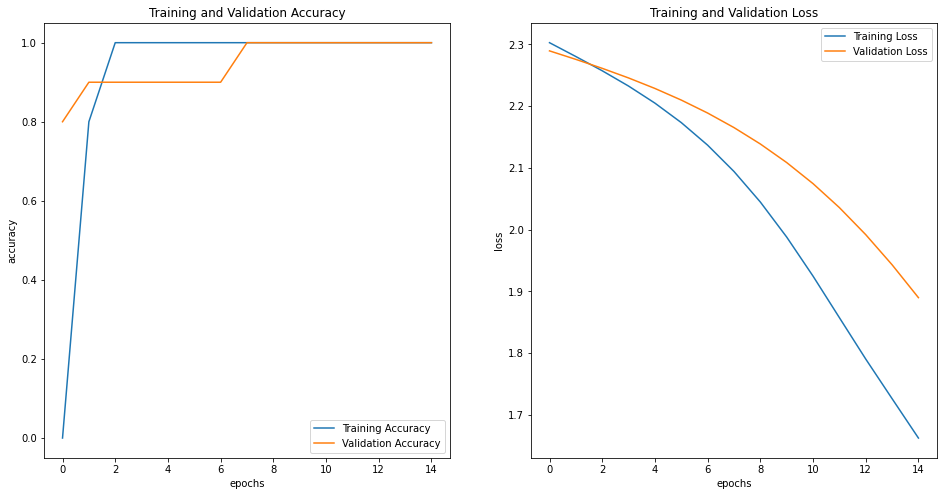

In [ ]:
# Learning curves

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss=history.history['loss']
val_loss=history.history['val_loss']

plt.figure(figsize=(16,8))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel("epochs")
plt.ylabel("accuracy")

plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel("epochs")
plt.ylabel("loss")
plt.show()

In [ ]:
import tensorflow as tf
tf.get_logger().setLevel('ERROR')

In [ ]:
def get_text(str_text):
    # print(str_text)
    input_text  = [str_text]
    df_input = pd.DataFrame(input_text,columns=['questions'])
    df_input
    return df_input

In [ ]:
from tensorflow.keras.models import load_model
model = model3
tokenizer_t = joblib.load('tokenizer_t.pkl')
vocab = joblib.load('vocab.pkl')

In [ ]:
def tokenizer(entry):
    tokens = entry.split()
    re_punc = re.compile('[%s]' % re.escape(string.punctuation))
    tokens = [re_punc.sub('', w) for w in tokens]
    tokens = [word for word in tokens if word.isalpha()]
    tokens = [lemmatizer.lemmatize(w.lower()) for w in tokens]
    # stop_words = set(stopwords.words('english'))
    # tokens = [w for w in tokens if not w in stop_words]
    tokens = [word.lower() for word in tokens if len(word) > 1]
    return tokens

In [ ]:
def remove_stop_words_for_input(tokenizer,df,feature):
    doc_without_stopwords = []
    entry = df[feature][0]
    tokens = tokenizer(entry)
    doc_without_stopwords.append(' '.join(tokens))
    df[feature] = doc_without_stopwords
    return df

In [ ]:
def encode_input_text(tokenizer_t,df,feature):
    t = tokenizer_t
    entry = entry = [df[feature][0]]
    encoded = t.texts_to_sequences(entry)
    padded = pad_sequences(encoded, maxlen=16, padding='post')
    return padded

In [ ]:
def get_pred(model,encoded_input):
    pred = np.argmax(model3.predict(encoded_input))
    return pred

In [ ]:
def bot_precausion(df_input,pred):
    words = df_input.questions[0].split()
    if len([w for w in words if w in vocab])==0 :
        pred = 1
    return pred

In [ ]:
def get_response(df2,pred):
    upper_bound = df2.groupby('labels').get_group(pred).shape[0]
    r = np.random.randint(0,upper_bound)
    responses = list(df2.groupby('labels').get_group(pred).response)
    return responses[r]

In [ ]:
def bot_response(response,):
    print(response)

In [ ]:
df_input = get_text("What is the meaning of bitcoin ?")


tokenizer_t = joblib.load('tokenizer_t.pkl')
vocab = joblib.load('vocab.pkl')

df_input = remove_stop_words_for_input(tokenizer,df_input,'questions')
encoded_input = encode_input_text(tokenizer_t,df_input,'questions')
pred = get_pred(model3,encoded_input)
pred = bot_precausion(df_input,pred)

response = get_response(df2,df_input)
bot_response(response)

ValueError: ignored